# Семинар 3. Одна задача оптимального управления — две численные постановки

Рассмотрим двойной интегратор
$$
\dot x_1=x_2,\qquad \dot x_2=u,
$$
с начальным условием
$$
x(0)=
\begin{pmatrix}
0\\
0
\end{pmatrix}.
$$

За время $T=2$ хотим приблизиться к состоянию
$$
x_{\mathrm{target}}=
\begin{pmatrix}
1\\
0
\end{pmatrix},
$$
при ограничении
$$
-1\le u(t)\le 1.
$$

Будем минимизировать
$$
J=
w_1(x_1(T)-1)^2+
w_2x_2(T)^2+
\lambda\int_0^T u^2(t)\,dt.
$$

После дискретизации одну и ту же задачу запишем двумя способами.

**A. Только управление — reduced formulation (single shooting).**  
Неизвестные — $u_0,\ldots,u_{N-1}$. Для каждого нового управления состояние вычисляется вперёд по динамике.

**B. Состояние и управление — direct transcription.**  
Неизвестные — $x_0,\ldots,x_N,u_0,\ldots,u_{N-1}$. Динамика записывается как система ограничений.

Это пока **не два способа дискретизации ОДУ**: сетка и формула перехода в обоих случаях будут одинаковыми. Мы сравниваем две постановки конечномерной задачи оптимизации.

Потом отдельно сравним две дискретизации динамики: Euler и точный переход.

Задача специально выбрана простой: после дискретизации она остаётся выпуклой. Поэтому обе постановки должны давать практически один и тот же минимум. Если результаты заметно различаются, сначала нужно искать причину в реализации или настройках solver'а.

## 0. Импорт

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from scipy.optimize import minimize, NonlinearConstraint

## 1. Дискретная динамика

Разобьём $[0,T]$ на $N$ одинаковых интервалов:
$$
h=\frac{T}{N}.
$$

Управление считаем постоянным на каждом интервале:
$$
u(t)=u_k,\qquad t\in[t_k,t_{k+1}).
$$

Для двойного интегратора точный переход за один шаг имеет вид
$$
x_{1,k+1}
=
x_{1,k}+h x_{2,k}+\frac{h^2}{2}u_k,
$$
$$
x_{2,k+1}
=
x_{2,k}+hu_k.
$$

Перед запуском следующей ячейки:

1. сколько компонент у $x_k$;
2. сколько значений управления будет при $N=20$;
3. почему состояний будет $N+1$, а управлений — $N$?

In [2]:
T = 2.0
N = 20
h = T / N

x0 = np.array([0.0, 0.0])
x_target = np.array([1.0, 0.0])

w1 = 100.0
w2 = 20.0
lam = 0.05


def step_exact(x, u, h):
    return np.array([
        x[0] + h * x[1] + 0.5 * h**2 * u,
        x[1] + h * u,
    ])

### Прямая симуляция

Если весь вектор управления уже известен, состояние можно последовательно вычислить от $t=0$ до $t=T$.

Обратите внимание на
```python
x = np.zeros((N + 1, 2))
```

Что означает каждая из двух размерностей этого массива?

In [3]:
def simulate(u, step=step_exact):
    N_local = len(u)
    h_local = T / N_local

    x = np.zeros((N_local + 1, 2))
    x[0] = x0

    for k in range(N_local):
        x[k + 1] = step(x[k], u[k], h_local)

    return x

### До оптимизации

Проверим три простых управления:

- $u(t)=0$;
- $u(t)=1$;
- сначала $u=1$, затем $u=-1$.

До запуска попробуйте угадать, какое из них лучше всего приблизит систему к $(1,0)$.

In [4]:
u_zero = np.zeros(N)
u_one = np.ones(N)
u_switch = np.r_[np.ones(N // 2), -np.ones(N - N // 2)]

controls = {
    "u = 0": u_zero,
    "u = 1": u_one,
    "u = +1 / -1": u_switch,
}

for name, u in controls.items():
    x = simulate(u)
    print(f"{name:12s} -> x(T) = {x[-1]}")

u = 0        -> x(T) = [0. 0.]
u = 1        -> x(T) = [2. 2.]
u = +1 / -1  -> x(T) = [1.00000000e+00 2.77555756e-17]


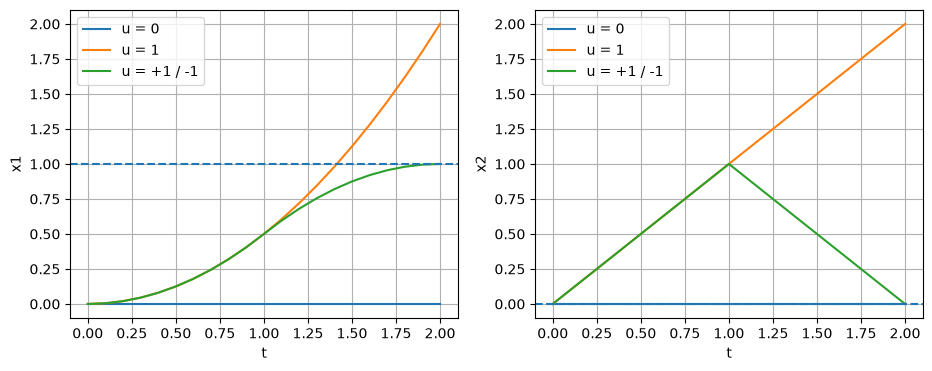

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, u in controls.items():
    x = simulate(u)
    t_x = np.linspace(0, T, len(x))
    ax[0].plot(t_x, x[:, 0], label=name)
    ax[1].plot(t_x, x[:, 1], label=name)

ax[0].axhline(1, linestyle="--")
ax[0].set_xlabel("t")
ax[0].set_ylabel("x1")
ax[0].grid()
ax[0].legend()

ax[1].axhline(0, linestyle="--")
ax[1].set_xlabel("t")
ax[1].set_ylabel("x2")
ax[1].grid()
ax[1].legend()

plt.show()

## 2. Постановка A: только управление

Оптимизируем
$$
u=(u_0,\ldots,u_{N-1})\in[-1,1]^N.
$$

Для каждого нового $u$ функция `objective_u`:

1. вычисляет траекторию;
2. берёт конечное состояние;
3. считает штраф за ошибку в конечной точке;
4. добавляет стоимость управления.

Состояния $x_k$ здесь **не являются переменными оптимизатора**. Они однозначно восстанавливаются по $u$.

Такую постановку часто называют reduced formulation; в задачах ОУ близкий по смыслу термин — single shooting.

In [6]:
def objective_u(u):
    x = simulate(u)
    e = x[-1] - x_target

    terminal_cost = w1 * e[0]**2 + w2 * e[1]**2
    control_cost = lam * (T / len(u)) * np.sum(u**2)

    return terminal_cost + control_cost

### Два метода `scipy.optimize`

Ограничение $-1\le u_k\le1$ здесь задаётся через `bounds`.

Сравним:

- `L-BFGS-B`;
- `SLSQP`.

Перед запуском ответьте:

1. сколько здесь переменных оптимизации;
2. есть ли отдельные ограничения на динамику;
3. почему `L-BFGS-B`, который умеет работать с bounds, подходит к этой постановке?

Для более честного сравнения явно зададим достаточно строгие tolerances. Значение `success=True` само по себе ещё не гарантирует, что два solver'а нашли решения одинакового качества.

In [7]:
def solve_control_only(method):
    u0_guess = np.zeros(N)
    bounds_u = [(-1.0, 1.0)] * N

    options = {"maxiter": 1000}

    if method == "L-BFGS-B":
        options["ftol"] = 1e-12
    elif method == "SLSQP":
        options["ftol"] = 1e-10

    start = perf_counter()

    res = minimize(
        objective_u,
        u0_guess,
        method=method,
        bounds=bounds_u,
        options=options,
    )

    elapsed = perf_counter() - start
    return res, elapsed


control_only_results = {}

for method in ["L-BFGS-B", "SLSQP"]:
    res, elapsed = solve_control_only(method)
    control_only_results[method] = (res, elapsed)

    x = simulate(res.x)

    print(
        f"{method:10s}  "
        f"success={res.success}  "
        f"J={res.fun:.8f}  "
        f"nit={res.nit}  "
        f"nfev={res.nfev}  "
        f"time={elapsed:.3f}s  "
        f"x(T)={x[-1]}"
    )

L-BFGS-B    success=True  J=0.09001945  nit=23  nfev=630  time=0.013s  x(T)=[0.99749516 0.01244654]
SLSQP       success=True  J=0.09001945  nit=15  nfev=317  time=0.008s  x(T)=[0.99749512 0.01244648]


### Сравните решения

Если оба метода решили задачу с достаточной точностью, значения $J$ и найденные управления должны быть близкими.

Поскольку управление кусочно-постоянное, для его изображения удобно использовать `plt.stairs`.

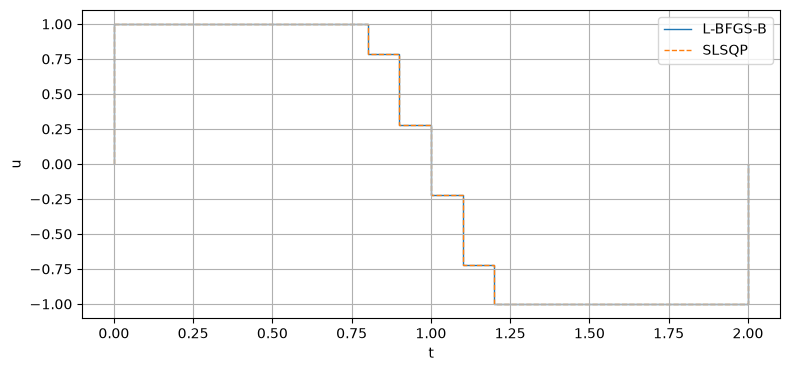

In [8]:
t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))

for method, (res, _) in control_only_results.items():
    plt.stairs(res.x, t_edges, label=method, linestyle="-" if method == "L-BFGS-B" else "--")

plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

### Быстрая проверка

Ответьте:

1. насколько близки значения функционала;
2. насколько близки найденные управления;
3. какой метод сделал меньше итераций;
4. означает ли меньшее `nfev`, что метод обязательно лучше;
5. почему при сравнении solver'ов нужно смотреть не только на `success`, но и на значение $J$ и выполнение ограничений?

## 3. Постановка B: состояния тоже становятся переменными

Теперь используем direct transcription. Неизвестным будет вектор
$$
z=
(x_0,x_1,\ldots,x_N,u_0,\ldots,u_{N-1}).
$$

Для $N=20$ переменных станет заметно больше.

Сначала посчитайте размерность $z$ самостоятельно. Затем сравните её с количеством равенств, которыми задаётся динамика.

In [9]:
def pack(x, u):
    return np.concatenate([x.ravel(), u])


def unpack(z):
    nx = 2 * (N + 1)

    x = z[:nx].reshape(N + 1, 2)
    u = z[nx:]

    return x, u


n_z = 2 * (N + 1) + N
n_eq = 2 * (N + 1)  # x(0)=x0 и по 2 уравнения динамики на каждом шаге

print("Переменных:", n_z)
print("Равенств:", n_eq)
print("Степеней свободы после учёта равенств:", n_z - n_eq)

Переменных: 62
Равенств: 42
Степеней свободы после учёта равенств: 20


### Что стало с динамикой?

Раньше состояние автоматически вычислялось функцией `simulate`.

Теперь оптимизатор свободно меняет и $x$, и $u$. Поэтому отдельно потребуем
$$
x_0=x_{\mathrm{init}},
$$
а для каждого $k$
$$
x_{k+1}=F(x_k,u_k).
$$

Запишем эти равенства как
$$
c(z)=0.
$$

При $N=20$ получаем 62 переменные и 42 равенства. После их учёта остаётся 20 степеней свободы — столько же, сколько компонент управления в первой постановке.

То есть две постановки описывают одну и ту же дискретную задачу, просто по-разному организуют переменные и ограничения.

In [10]:
def dynamics_residual(z):
    x, u = unpack(z)

    residuals = [x[0] - x0]

    for k in range(N):
        residuals.append(
            x[k + 1] - step_exact(x[k], u[k], h)
        )

    return np.concatenate(residuals)

Функционал остаётся тем же. Разница только в том, откуда берётся состояние: теперь оно извлекается прямо из $z$.

In [11]:
def objective_z(z):
    x, u = unpack(z)

    e = x[-1] - x_target

    terminal_cost = w1 * e[0]**2 + w2 * e[1]**2
    control_cost = lam * h * np.sum(u**2)

    return terminal_cost + control_cost

### Начальное приближение

Возьмём $u=0$ и построим соответствующую ему траекторию. Это автоматически даст начальную точку, которая уже удовлетворяет динамике.

In [12]:
u_guess = np.zeros(N)
x_guess = simulate(u_guess)
z0 = pack(x_guess, u_guess)

print("Размер z0:", len(z0))
print("max |c(z0)| =", np.max(np.abs(dynamics_residual(z0))))

Размер z0: 62
max |c(z0)| = 0.0


### Ограничения на переменные

Для состояний пока bounds не задаём. Для последних $N$ компонент, то есть для управления, остаётся
$$
-1\le u_k\le1.
$$

In [13]:
bounds_z = (
    [(None, None)] * (2 * (N + 1))
    + [(-1.0, 1.0)] * N
)

### Решаем через `SLSQP`

Теперь одного `bounds` недостаточно: нужно ещё передать равенства $c(z)=0$.

In [14]:
eq_constraint = {
    "type": "eq",
    "fun": dynamics_residual,
}

start = perf_counter()

res_tr_slsqp = minimize(
    objective_z,
    z0,
    method="SLSQP",
    bounds=bounds_z,
    constraints=eq_constraint,
    options={
        "maxiter": 500,
        "ftol": 1e-10,
    },
)

time_tr_slsqp = perf_counter() - start

x_tr_slsqp, u_tr_slsqp = unpack(res_tr_slsqp.x)

print("success:", res_tr_slsqp.success)
print("J:", res_tr_slsqp.fun)
print("nit:", res_tr_slsqp.nit)
print("nfev:", res_tr_slsqp.nfev)
print("time:", time_tr_slsqp)
print("x(T):", x_tr_slsqp[-1])
print("max dynamic residual:",
      np.max(np.abs(dynamics_residual(res_tr_slsqp.x))))

success: True
J: 0.090019447692534
nit: 22
nfev: 1387
time: 0.03551962499477668
x(T): [0.99749509 0.0124466 ]
max dynamic residual: 3.4139358007223564e-13


### Ещё один solver: `trust-constr`

`L-BFGS-B` умеет работать с bounds, но не с общими равенствами вида $c(z)=0$. Поэтому для direct transcription сравним `SLSQP` с `trust-constr`.

В этой конкретной задаче ограничения динамики линейны, хотя мы передаём их через общий интерфейс `NonlinearConstraint`. Это сделано, чтобы тот же шаблон потом можно было использовать и для нелинейной динамики.

In [15]:
nonlinear_constraint = NonlinearConstraint(
    dynamics_residual,
    0.0,
    0.0,
)

start = perf_counter()

res_tr_trust = minimize(
    objective_z,
    z0,
    method="trust-constr",
    bounds=bounds_z,
    constraints=[nonlinear_constraint],
    options={
        "maxiter": 300,
        "gtol": 1e-8,
    },
)

time_tr_trust = perf_counter() - start

x_tr_trust, u_tr_trust = unpack(res_tr_trust.x)

print("success:", res_tr_trust.success)
print("J:", res_tr_trust.fun)
print("nit:", res_tr_trust.nit)
print("nfev:", res_tr_trust.nfev)
print("time:", time_tr_trust)
print("x(T):", x_tr_trust[-1])
print("max dynamic residual:",
      np.max(np.abs(dynamics_residual(res_tr_trust.x))))

success: True
J: 0.09001961289461909
nit: 131
nfev: 7749
time: 0.29487812500155997
x(T): [0.99749507 0.01244681]
max dynamic residual: 1.1102230246251565e-16


## 4. Сводное сравнение

Соберём характеристики всех четырёх запусков:

- `success`;
- значение функционала;
- ошибку в конечной точке;
- расход управления;
- число итераций;
- `nfev` и `njev`;
- время;
- максимальную невязку динамики.

С `nfev` нужна осторожность. В reduced formulation один вызов `objective_u` включает полную симуляцию траектории. В direct transcription `objective_z` дешевле, зато solver отдельно вычисляет ограничения и их производные. Поэтому `nfev` между двумя постановками нельзя считать прямой мерой общей вычислительной работы.

Время тоже зависит от компьютера и конкретного запуска. Здесь оно нужно скорее для общей картины.

In [16]:
def control_effort(u):
    return h * np.sum(u**2)


def terminal_error(x):
    return np.linalg.norm(x[-1] - x_target)


rows = []

for method, (res, elapsed) in control_only_results.items():
    u = res.x
    x = simulate(u)

    z_check = pack(x, u)

    rows.append({
        "formulation": "control only",
        "method": method,
        "success": res.success,
        "n_variables": len(u),
        "J": res.fun,
        "terminal_error": terminal_error(x),
        "control_effort": control_effort(u),
        "nit": res.nit,
        "nfev": res.nfev,
        "njev": getattr(res, "njev", np.nan),
        "time_s": elapsed,
        "dyn_residual": np.max(np.abs(dynamics_residual(z_check))),
    })


for method, res, elapsed in [
    ("SLSQP", res_tr_slsqp, time_tr_slsqp),
    ("trust-constr", res_tr_trust, time_tr_trust),
]:
    x, u = unpack(res.x)

    rows.append({
        "formulation": "state + control",
        "method": method,
        "success": res.success,
        "n_variables": len(res.x),
        "J": res.fun,
        "terminal_error": terminal_error(x),
        "control_effort": control_effort(u),
        "nit": res.nit,
        "nfev": res.nfev,
        "njev": getattr(res, "njev", np.nan),
        "time_s": elapsed,
        "dyn_residual": np.max(np.abs(dynamics_residual(res.x))),
    })


comparison = pd.DataFrame(rows)
comparison

,formulation,method,success,n_variables,J,terminal_error,control_effort,nit,nfev,njev,time_s,dyn_residual
0,control only,L-BFGS-B,True,20,0.090019,0.012696,1.725874,23,630,30,0.013478,0.000000e+00
1,control only,SLSQP,True,20,0.090019,0.012696,1.725874,15,317,15,0.008436,0.000000e+00
2,state + control,SLSQP,True,62,0.090019,0.012696,1.725873,22,1387,22,0.035520,3.413936e-13
3,state + control,trust-constr,True,62,0.090020,0.012696,1.725874,131,7749,123,0.294878,1.110223e-16


### Сравним сами решения

Возьмём:

- `L-BFGS-B` для reduced formulation;
- `SLSQP` для direct transcription.

В нашей выпуклой задаче они должны привести практически к одной и той же траектории и одному управлению.

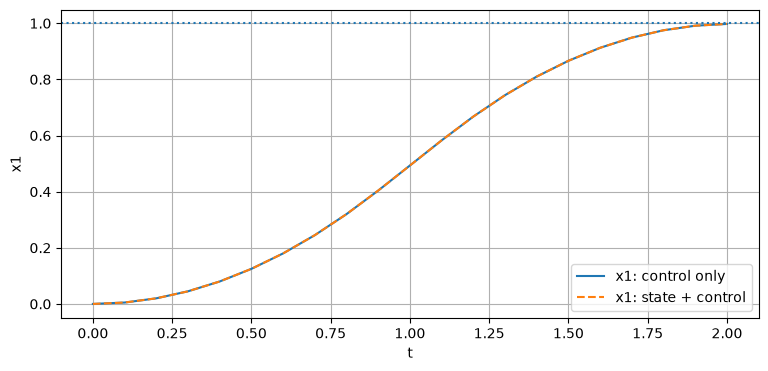

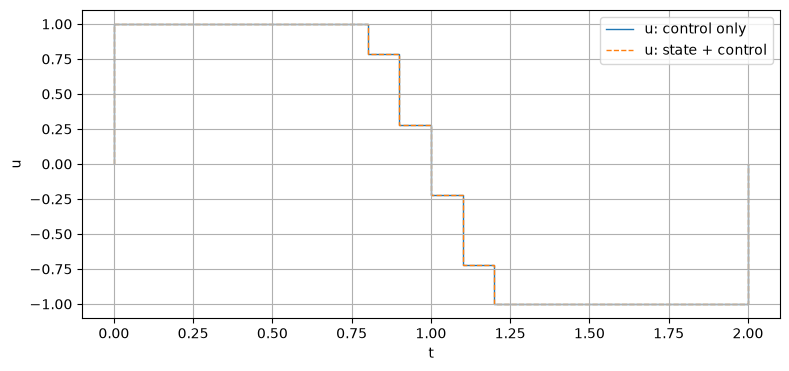

max |u_A - u_B| = 2.2938856966914223e-05
max |x_A - x_B| = 2.234495117270363e-06


In [17]:
res_a = control_only_results["L-BFGS-B"][0]
u_a = res_a.x
x_a = simulate(u_a)

u_b = u_tr_slsqp
x_b = x_tr_slsqp

t_x = np.linspace(0, T, N + 1)
t_edges = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))
plt.plot(t_x, x_a[:, 0], label="x1: control only")
plt.plot(t_x, x_b[:, 0], "--", label="x1: state + control")
plt.axhline(1, linestyle=":")
plt.xlabel("t")
plt.ylabel("x1")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.stairs(u_a, t_edges, label="u: control only")
plt.stairs(u_b, t_edges, linestyle="--", label="u: state + control")
plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

print("max |u_A - u_B| =", np.max(np.abs(u_a - u_b)))
print("max |x_A - x_B| =", np.max(np.abs(x_a - x_b)))

### Обсудите

1. Почему две постановки дают почти одно и то же решение?
2. Почему во второй постановке переменных больше, но после учёта равенств число степеней свободы совпадает с первой?
3. В какой постановке динамика выполняется автоматически?
4. В какой постановке динамика становится ограничением оптимизации?
5. Почему `L-BFGS-B` можно напрямую использовать в первой постановке, но не во второй?
6. Какая постановка будет удобнее, если появятся ограничения на состояние?
7. Можно ли по этой одной задаче сделать вывод, что одна постановка всегда быстрее другой?

## 5. Теперь сравним две дискретизации динамики

До этого формула перехода была одной и той же — менялась только постановка оптимизации.

Теперь вместо точного перехода возьмём Euler:
$$
x_{1,k+1}=x_{1,k}+h x_{2,k},
$$
$$
x_{2,k+1}=x_{2,k}+h u_k.
$$

Для двойного интегратора точный шаг известен, поэтому можно напрямую увидеть ошибку Euler.

Важно различать две ошибки:

- solver может неточно решить уже дискретизированную задачу;
- сама дискретная модель может неточно описывать исходную непрерывную систему.

Euler optimization success: True
J on Euler model: 0.09033293221251583
Same u, J on exact dynamics: 0.09005512127644259
Exact-model optimum J: 0.0900194476857899

Euler model x(T): [0.99741691 0.01219411]
Same u with exact dynamics x(T): [0.99802661 0.01219411]
Endpoint model error: 0.00060970535207161
max |u_Euler - u_exact| = 0.024147613850804106


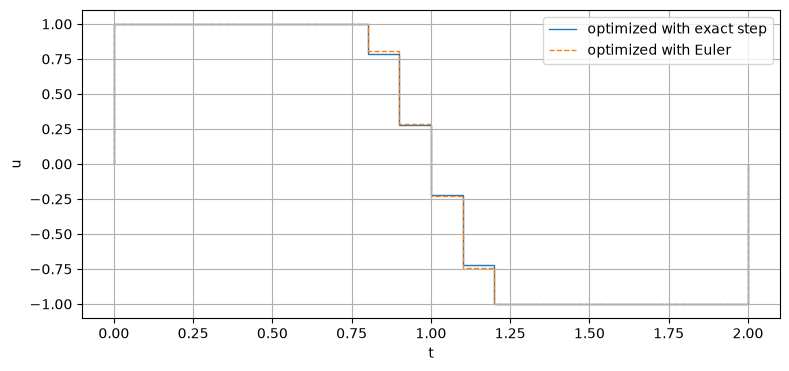

In [18]:
def step_euler(x, u, h):
    return np.array([
        x[0] + h * x[1],
        x[1] + h * u,
    ])


def objective_u_euler(u):
    x = simulate(u, step=step_euler)
    e = x[-1] - x_target

    return (
        w1 * e[0]**2
        + w2 * e[1]**2
        + lam * (T / len(u)) * np.sum(u**2)
    )


res_euler = minimize(
    objective_u_euler,
    np.zeros(N),
    method="L-BFGS-B",
    bounds=[(-1.0, 1.0)] * N,
    options={
        "maxiter": 1000,
        "ftol": 1e-12,
    },
)

u_euler = res_euler.x

x_euler_model = simulate(u_euler, step=step_euler)
x_euler_checked_exact = simulate(u_euler, step=step_exact)

print("Euler optimization success:", res_euler.success)
print("J on Euler model:", res_euler.fun)
print("Same u, J on exact dynamics:", objective_u(u_euler))
print("Exact-model optimum J:", res_a.fun)
print()
print("Euler model x(T):", x_euler_model[-1])
print("Same u with exact dynamics x(T):", x_euler_checked_exact[-1])
print(
    "Endpoint model error:",
    np.linalg.norm(x_euler_checked_exact[-1] - x_euler_model[-1])
)
print(
    "max |u_Euler - u_exact| =",
    np.max(np.abs(u_euler - u_a))
)

plt.figure(figsize=(9, 4))
plt.stairs(u_a, t_edges, label="optimized with exact step")
plt.stairs(u_euler, t_edges, linestyle="--", label="optimized with Euler")
plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-1.1, 1.1)
plt.grid()
plt.legend()
plt.show()

Оптимизатор может очень хорошо решить **Euler-модель**, но управление, найденное для этой модели, всё равно стоит проверить на более точной динамике.

### В конце пары

Сформулируйте своими словами три разных сравнения:

1. reduced formulation против direct transcription;
2. разные методы `scipy.optimize` внутри выбранной постановки;
3. Euler против точного перехода.

Это три разных источника различий в численных результатах.

# Домашняя работа — срок 2 недели

Продолжайте работу в этом notebook.

Перед первым заданием приведите функции к виду, в котором $N$ не приходится менять вручную в нескольких местах. Например, сделайте $N$ аргументом функций, которые решают задачу. То же самое пригодится позже для $\lambda$.

## 1. Сгущение сетки

Повторите расчёты для
$$
N=10,\quad20,\quad40,\quad80.
$$

Для каждого $N$ решите задачу:

- reduced formulation методом `L-BFGS-B`;
- direct transcription методом `SLSQP`.

Используйте те же tolerances, что и на семинаре.

Составьте таблицу:

`N`, `formulation`, `n_variables`, `J`, `terminal_error`, `control_effort`, `nit`, `nfev`, `time_s`.

Время одного запуска — шумная величина. Если компьютер позволяет, запустите каждый вариант 3 раза и запишите медианное время.

Постройте зависимости времени решения и $J$ от $N$.

Ответьте:

1. как растёт размерность обеих задач;
2. стабилизируются ли $J$ и управление при сгущении сетки;
3. какая постановка оказалась быстрее именно в этом эксперименте;
4. почему этот результат нельзя автоматически переносить на все задачи оптимального управления?

In [24]:
def unpack_n(z, N):
    nx = 2 * (N + 1)
    x = z[:nx].reshape(N + 1, 2)
    u = z[nx:]
    return x, u


def objective_n(x, u, lam_value):
    e = x[-1] - x_target
    h = T / len(u)

    return (
        w1 * e[0]**2
        + w2 * e[1]**2
        + lam_value * h * np.sum(u**2)
    )


def dynamics_residual_n(z, N):
    x, u = unpack_n(z, N)
    h = T / N

    residuals = [x[0] - x0]

    for k in range(N):
        residuals.append(
            x[k + 1] - step_exact(x[k], u[k], h)
        )

    return np.concatenate(residuals)


def solve_reduced(N, lam_value=0.05, method="L-BFGS-B", step=step_exact):
    u0_guess = np.zeros(N)
    bounds_u = [(-1.0, 1.0)] * N

    def objective(u):
        return objective_n(simulate(u, step=step), u, lam_value)

    options = {"maxiter": 1000}

    if method == "L-BFGS-B":
        options["ftol"] = 1e-12
    elif method == "SLSQP":
        options["ftol"] = 1e-10

    start = perf_counter()

    res = minimize(
        objective,
        u0_guess,
        method=method,
        bounds=bounds_u,
        options=options,
    )

    return res, perf_counter() - start


def solve_direct(N, lam_value=0.05, method="SLSQP"):
    u0_guess = np.zeros(N)
    x0_guess = simulate(u0_guess)
    z0 = pack(x0_guess, u0_guess)

    bounds_z = (
        [(None, None)] * (2 * (N + 1))
        + [(-1.0, 1.0)] * N
    )

    def objective(z):
        x, u = unpack_n(z, N)
        return objective_n(x, u, lam_value)

    eq_constraint = {
        "type": "eq",
        "fun": lambda z: dynamics_residual_n(z, N),
    }

    start = perf_counter()

    res = minimize(
        objective,
        z0,
        method=method,
        bounds=bounds_z,
        constraints=eq_constraint,
        options={"maxiter": 500, "ftol": 1e-10},
    )

    return res, perf_counter() - start

In [25]:
# Ваш код для задания 1
N_values = [10, 20, 40, 80]
rows = []
controls = {}

for n in N_values:
    for formulation in ["reduced", "direct transcription"]:
        if formulation == "reduced":
            results = [solve_reduced(n, lam) for _ in range(3)]
        else:
            results = [solve_direct(n, lam) for _ in range(3)]

        res = results[0][0]
        elapsed = np.median([t for _, t in results])

        if formulation == "reduced":
            u = res.x
            x = simulate(u)
        else:
            x, u = unpack_n(res.x, n)

        controls[(n, formulation)] = u.copy()

        rows.append({
            "N": n,
            "formulation": formulation,
            "n_variables": len(res.x),
            "J": res.fun,
            "terminal_error": terminal_error(x),
            "control_effort": (T / n) * np.sum(u**2),
            "nit": res.nit,
            "nfev": res.nfev,
            "time_s": elapsed,
        })

        if not res.success:
            print(f"N={n}, {formulation}: {res.message}")

comparison_hw1 = pd.DataFrame(rows)

display(comparison_hw1.round({
    "J": 8,
    "terminal_error": 8,
    "control_effort": 6,
    "time_s": 4,
}))

,N,formulation,n_variables,J,terminal_error,control_effort,nit,nfev,time_s
0,10,reduced,10,0.091487,0.014758,1.728883,33,605,0.0116
1,10,direct transcription,32,0.091454,0.014513,1.731709,11,364,0.0071
2,20,reduced,20,0.090019,0.012696,1.725874,23,630,0.0109
3,20,direct transcription,62,0.090019,0.012696,1.725873,22,1387,0.0354
4,40,reduced,40,0.089715,0.012311,1.724246,49,2419,0.0638
5,40,direct transcription,122,0.089715,0.012311,1.724246,29,3569,0.1768
6,80,reduced,80,0.089642,0.012223,1.723776,39,3645,0.1652
7,80,direct transcription,242,0.089642,0.012226,1.723745,48,11666,1.0948


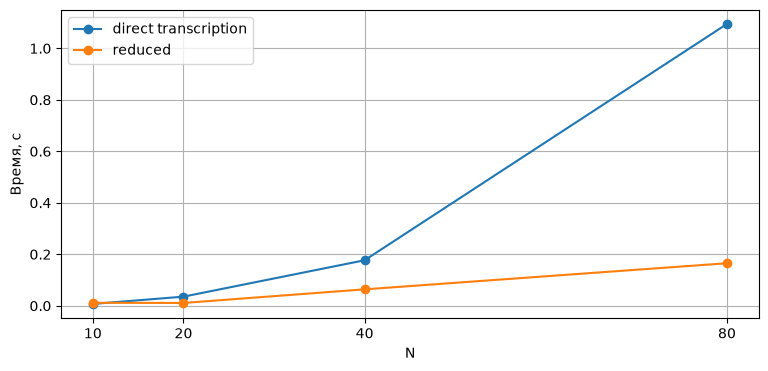

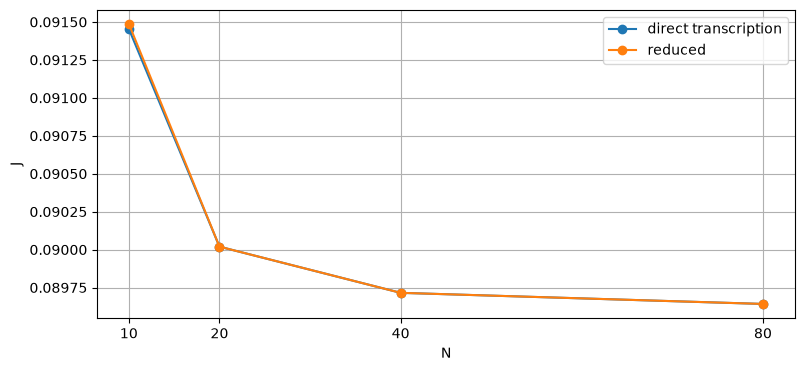

In [26]:
plt.figure(figsize=(9, 4))

for formulation, group in comparison_hw1.groupby("formulation"):
    plt.plot(group["N"], group["time_s"], "o-", label=formulation)

plt.xlabel("N")
plt.ylabel("Время, с")
plt.xticks(N_values)
plt.grid()
plt.legend()
plt.show()


plt.figure(figsize=(9, 4))

for formulation, group in comparison_hw1.groupby("formulation"):
    plt.plot(group["N"], group["J"], "o-", label=formulation)

plt.xlabel("N")
plt.ylabel("J")
plt.xticks(N_values)
plt.grid()
plt.legend()
plt.show()

In [27]:
rows_control = []

for formulation in ["reduced", "direct transcription"]:
    for n in N_values[:-1]:
        u_coarse = controls[(n, formulation)]
        u_fine = controls[(2 * n, formulation)]

        difference = u_fine - np.repeat(u_coarse, 2)
        error = np.sqrt((T / (2 * n)) * np.sum(difference**2))

        rows_control.append({
            "formulation": formulation,
            "N -> 2N": f"{n} -> {2 * n}",
            "L2_difference": error,
        })

control_convergence = pd.DataFrame(rows_control)
display(control_convergence)

,formulation,N -> 2N,L2_difference
0,reduced,10 -> 20,0.164076
1,reduced,20 -> 40,0.077558
2,reduced,40 -> 80,0.038223
3,direct transcription,10 -> 20,0.164813
4,direct transcription,20 -> 40,0.077557
5,direct transcription,40 -> 80,0.038222


<span style="color:red">Ответ:</span>

1. в reduced formulation число переменных равно $N$, а в direct transcription — $3N+2$, поскольку оптимизируются $N$ управлений и $2(N+1)$ компонент состояния, таким образом, размерность обеих задач растёт линейно, но во второй постановке примерно в три раза больше переменных

2. при сгущении сетки значение функционала стабилизируется и приближается к непрерывному оптимуму $J^*\approx 0.08962$, при $N=80$ обе постановки дают $J\approx 0.089642$, управление также сходится, что подтверждается уменьшением разности в норме $L^2$ с $0.164$ до $0.038$

3. в данном эксперименте reduced formulation оказалась быстрее при $N=20,40,80$, особенно при $N=80$ ($0.1652$ с против $1.0948$ с), однако при $N=10$ быстрее была direct transcription ($0.0071$ с против $0.0116$ с)

4. полученные результаты нельзя обобщать на все задачи оптимального управления, поскольку вычислительная эффективность зависит от размерности системы, структуры динамики и ограничений, используемого оптимизатора и реализации производных, в частности, direct transcription может быть эффективнее при использовании разреженных матриц производных

## 2. Сравнение solver'ов

Для $N=20$ сравните:

### Reduced formulation

- `L-BFGS-B`;
- `SLSQP`;
- `Powell`.

### Direct transcription

- `SLSQP`;
- `trust-constr`.

Для каждого запуска сохраните:

`success`, `J`, `nit`, `nfev`, `time_s`.

Кроме этого, посчитайте относительный разрыв по функционалу относительно лучшего найденного значения:
$$
\mathrm{gap}
=
\frac{J-J_{\min}}{|J_{\min}|}.
$$

`Powell` здесь специально включён как метод без использования градиента. Не удивляйтесь, если `success=True` у него не означает такое же качество решения, как у других методов.

Сделайте таблицу и короткий вывод. Не выбирайте «лучший solver вообще» — вывод относится только к этой задаче, этим tolerances и этой реализации.

In [28]:
# Ваш код для задания 2
n = 20
runs = []

for method in ["L-BFGS-B", "SLSQP", "Powell"]:
    res, elapsed = solve_reduced(n, lam, method=method)
    runs.append(("reduced", method, res, elapsed))

res, elapsed = solve_direct(n, lam, method="SLSQP")
runs.append(("direct transcription", "SLSQP", res, elapsed))

u_guess = np.zeros(n)
z0 = pack(simulate(u_guess), u_guess)

bounds = (
    [(None, None)] * (2 * (n + 1))
    + [(-1.0, 1.0)] * n
)

constraint = NonlinearConstraint(
    lambda z: dynamics_residual_n(z, n),
    0.0,
    0.0,
)

start = perf_counter()

res = minimize(
    lambda z: objective_n(*unpack_n(z, n), lam),
    z0,
    method="trust-constr",
    bounds=bounds,
    constraints=[constraint],
    options={"maxiter": 300, "gtol": 1e-8},
)

elapsed = perf_counter() - start
runs.append(("direct transcription", "trust-constr", res, elapsed))

rows = []

for formulation, method, res, elapsed in runs:
    rows.append({
        "formulation": formulation,
        "solver": method,
        "success": res.success,
        "J": res.fun,
        "nit": res.nit,
        "nfev": res.nfev,
        "time_s": elapsed,
    })

comparison_hw2 = pd.DataFrame(rows)

J_min = comparison_hw2["J"].min()
comparison_hw2["gap"] = (comparison_hw2["J"] - J_min) / abs(J_min)

display(comparison_hw2.round({
    "J": 9,
    "time_s": 4,
    "gap": 8,
}))

,formulation,solver,success,J,nit,nfev,time_s,gap
0,reduced,L-BFGS-B,True,0.090019,23,630,0.0174,0.000000
1,reduced,SLSQP,True,0.090019,15,317,0.0079,0.000000
2,reduced,Powell,True,0.166941,17,7909,0.1227,0.854495
3,direct transcription,SLSQP,True,0.090019,22,1387,0.0344,0.000000
4,direct transcription,trust-constr,True,0.090020,131,7749,0.2928,0.000002


<span style="color:red">Ответ:</span>

в данном эксперименте L-BFGS-B и SLSQP в обеих постановках получили практически одинаковые значения функционала $J\approx0.090019$, при этом наименьшее время показал SLSQP в reduced formulation ($0.0079$ с). Метод trust-constr также обеспечил высокую точность, но потребовал значительно больше времени. Powell оказался менее эффективным: несмотря на успешное завершение, относительный разрыв по функционалу составил около $85.45\%$. Таким образом, для рассматриваемой задачи при заданных параметрах точности и реализации наиболее эффективным по сочетанию времени и качества решения оказался SLSQP в reduced formulation.

## 3. Euler против точного шага

Для
$$
N=10,\quad20,\quad40,\quad80
$$
решите reduced formulation дважды:

1. с `step_euler`;
2. с `step_exact`.

Для управления, найденного на Euler-модели, обязательно сделайте проверку на точной динамике.

Для каждого $N$ сохраните:

- $J$ на модели, на которой шла оптимизация;
- конечное состояние в этой модели;
- конечное состояние того же управления при точной динамике;
- норму разности этих конечных состояний;
- разность между оптимальными управлениями Euler и exact.

Постройте ошибку как функцию $N$.

Ответьте:

1. уменьшается ли ошибка при сгущении сетки;
2. чем эта ошибка отличается от ошибки, связанной с неточной остановкой optimizer'а?

In [29]:
# Ваш код для задания 3
N_values = [10, 20, 40, 80]
rows_hw3 = []

for n in N_values:
    res_euler, _ = solve_reduced(n, lam, step=step_euler)
    res_exact, _ = solve_reduced(n, lam, step=step_exact)

    u_euler = res_euler.x
    u_exact = res_exact.x

    x_euler_model = simulate(u_euler, step=step_euler)
    x_euler_checked = simulate(u_euler, step=step_exact)
    x_exact_model = simulate(u_exact, step=step_exact)

    state_error = np.linalg.norm(
        x_euler_model[-1] - x_euler_checked[-1]
    )
    control_difference = np.max(np.abs(u_euler - u_exact))

    rows_hw3.append({
        "N": n,
        "Euler_success": res_euler.success,
        "Exact_success": res_exact.success,
        "J_Euler": res_euler.fun,
        "J_Exact": res_exact.fun,
        "xT_Euler": np.round(x_euler_model[-1], 6),
        "xT_Euler_checked": np.round(x_euler_checked[-1], 6),
        "xT_Exact": np.round(x_exact_model[-1], 6),
        "state_error": state_error,
        "control_difference": control_difference,
    })

comparison_hw3 = pd.DataFrame(rows_hw3)

display(comparison_hw3.round({
    "J_Euler": 8,
    "J_Exact": 8,
    "state_error": 8,
    "control_difference": 8,
}))

,N,Euler_success,Exact_success,J_Euler,J_Exact,xT_Euler,xT_Euler_checked,xT_Exact,state_error,control_difference
0,10,True,True,0.092284,0.091487,"[0.996929, 0.013734]","[0.998302, 0.013734]","[0.99707, 0.014464]",0.001373,0.048847
1,20,True,True,0.090333,0.090019,"[0.997417, 0.012194]","[0.998027, 0.012194]","[0.997495, 0.012447]",0.000610,0.024148
2,40,True,True,0.089862,0.089715,"[0.997535, 0.011945]","[0.997834, 0.011945]","[0.997571, 0.012069]",0.000299,0.013158
3,80,True,True,0.089714,0.089642,"[0.99757, 0.011928]","[0.997719, 0.011928]","[0.997588, 0.011982]",0.000149,0.005817


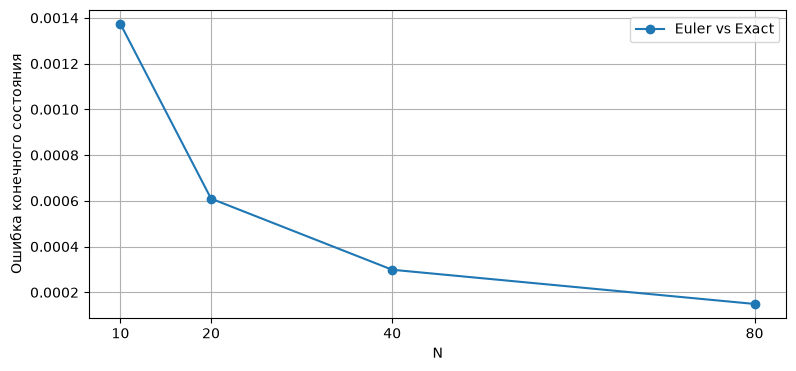

In [30]:
plt.figure(figsize=(9, 4))

plt.plot(
    comparison_hw3["N"],
    comparison_hw3["state_error"],
    "o-",
    label="Euler vs Exact"
)

plt.xlabel("N")
plt.ylabel("Ошибка конечного состояния")
plt.xticks(N_values)
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Ответ:</span>

1. при сгущении сетки ошибка конечного состояния уменьшается с $1.373\cdot10^{-3}$ при $N=10$ до $1.49\cdot10^{-4}$ при $N=80$, при удвоении $N$ ошибка уменьшается примерно вдвое, что соответствует первому порядку точности метода Эйлера, разность оптимальных управлений также сокращается с $0.048847$ до $0.005817$

2. ошибка дискретизации возникает из-за приближённого описания динамики методом Эйлера и сохраняется даже при точном решении дискретной задачи, тогда как ошибка оптимизации связана с неточной остановкой численного алгоритма до достижения минимума, первая уменьшается при сгущении сетки, а вторая — при повышении точности оптимизатора

## 4. Ограничение на состояние

Добавим
$$
|x_2(t)|\le0.8.
$$

Решите задачу двумя способами.

### A. Reduced formulation

Состояние не является переменной оптимизации. Поэтому ограничение нужно вычислять через `simulate(u)` и передавать в `SLSQP` как inequality constraint.

### B. Direct transcription

Компоненты $x_{2,k}$ уже входят в $z$. Здесь ограничение можно задать непосредственно как bounds на соответствующие компоненты состояния.

Сравните:

- объём и структуру кода;
- размерность;
- время;
- найденные $u(t)$ и $x_2(t)$;
- максимальное нарушение ограничения.

После этого ответьте: какая постановка оказалась удобнее именно после появления ограничения на состояние?

Это один из главных практических аргументов в пользу direct transcription: ограничения на состояния в нём обычно задаются естественнее.

In [ ]:
# Ваш код для задания 4
n = 20
limit = 0.8
u0_guess = np.zeros(n)

# Reduced formulation
def speed_constraint(u):
    v = simulate(u)[:, 1]
    return np.r_[limit - v, limit + v]


start = perf_counter()

res_reduced = minimize(
    lambda u: objective_n(simulate(u), u, lam),
    u0_guess,
    method="SLSQP",
    bounds=[(-1.0, 1.0)] * n,
    constraints={"type": "ineq", "fun": speed_constraint},
    options={"maxiter": 1000, "ftol": 1e-10},
)

time_reduced = perf_counter() - start

u_reduced = res_reduced.x
x_reduced = simulate(u_reduced)


# Direct transcription
z0 = pack(simulate(u0_guess), u0_guess)

bounds_z = (
    [(None, None)] * (2 * (n + 1))
    + [(-1.0, 1.0)] * n
)

for k in range(n + 1):
    bounds_z[2 * k + 1] = (-limit, limit)

start = perf_counter()

res_direct = minimize(
    lambda z: objective_n(*unpack_n(z, n), lam),
    z0,
    method="SLSQP",
    bounds=bounds_z,
    constraints={
        "type": "eq",
        "fun": lambda z: dynamics_residual_n(z, n),
    },
    options={"maxiter": 500, "ftol": 1e-10},
)

time_direct = perf_counter() - start

x_direct, u_direct = unpack_n(res_direct.x, n)


# Сравнение результатов
rows_hw4 = []

for formulation, res, elapsed, x, u in [
    ("reduced", res_reduced, time_reduced, x_reduced, u_reduced),
    ("direct transcription", res_direct, time_direct, x_direct, u_direct),
]:
    rows_hw4.append({
        "formulation": formulation,
        "success": res.success,
        "n_variables": len(res.x),
        "J": res.fun,
        "nit": res.nit,
        "nfev": res.nfev,
        "time_s": elapsed,
        "max_violation": max(0.0, np.max(np.abs(x[:, 1]) - limit)),
        "dyn_residual": np.max(
            np.abs(dynamics_residual_n(pack(x, u), n))
        ),
    })

comparison_hw4 = pd.DataFrame(rows_hw4)

display(comparison_hw4.round({
    "J": 8,
    "time_s": 4,
    "max_violation": 10,
    "dyn_residual": 10,
}))

print("max |u_reduced - u_direct| =", np.max(np.abs(u_reduced - u_direct)))
print("max |x2_reduced - x2_direct| =", np.max(np.abs(x_reduced[:, 1] - x_direct[:, 1])))

,formulation,success,n_variables,J,nit,nfev,time_s,max_violation,dyn_residual
0,reduced,True,20,0.118795,12,252,0.0160,0.0,0.0
1,direct transcription,True,62,0.118795,12,757,0.0253,0.0,0.0


max |u_reduced - u_direct| = 8.621866365299269e-08
max |x2_reduced - x2_direct| = 8.621879432624269e-09


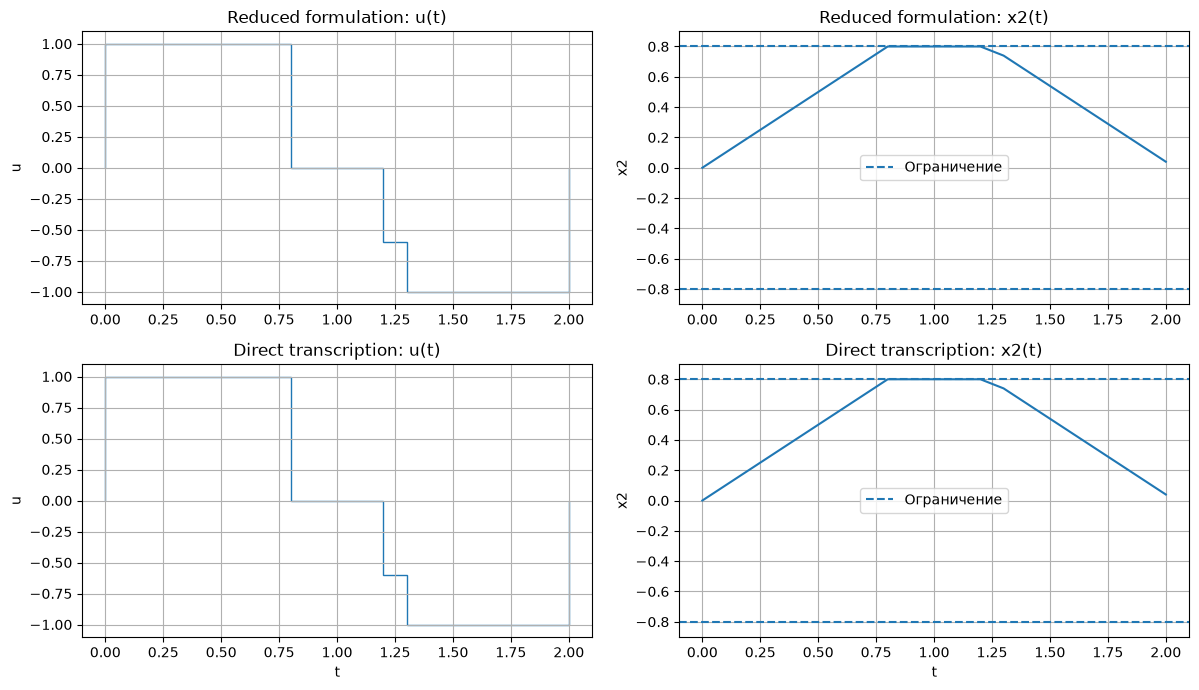

In [32]:
t_edges = np.linspace(0, T, n + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for i, (name, u, x) in enumerate([
    ("Reduced formulation", u_reduced, x_reduced),
    ("Direct transcription", u_direct, x_direct),
]):
    axes[i, 0].stairs(u, t_edges)
    axes[i, 0].set_title(f"{name}: u(t)")
    axes[i, 0].set_ylabel("u")
    axes[i, 0].set_ylim(-1.1, 1.1)
    axes[i, 0].grid()

    axes[i, 1].plot(t_edges, x[:, 1])
    axes[i, 1].axhline(limit, linestyle="--", label="Ограничение")
    axes[i, 1].axhline(-limit, linestyle="--")
    axes[i, 1].set_title(f"{name}: x2(t)")
    axes[i, 1].set_ylabel("x2")
    axes[i, 1].set_ylim(-0.9, 0.9)
    axes[i, 1].grid()
    axes[i, 1].legend()

for ax in axes[-1]:
    ax.set_xlabel("t")

plt.tight_layout()
plt.show()

<span style="color:red">Вывод:</span>

обе постановки дали практически одинаковые решения с $J\approx0.118795$, максимальная разность управлений составила $8.62\cdot10^{-8}$, ограничение на скорость выполняется без нарушений. Reduced formulation содержит 20 переменных и оказалась немного быстрее ($0.0160$ с против $0.0253$ с), тогда как direct transcription содержит 62 переменные. Однако после добавления ограничения на состояние direct transcription удобнее с точки зрения реализации, поскольку ограничение задаётся непосредственно через bounds на переменные состояния, а в reduced formulation требуется дополнительное вычисление траектории внутри функции ограничений. Таким образом, direct transcription обеспечивает более естественное задание ограничений на состояние, несмотря на большую размерность задачи.

## 5. Влияние веса управления

Возьмите
$$
\lambda=
10^{-3},\quad10^{-2},\quad10^{-1},\quad1.
$$

Для каждого $\lambda$ решите задачу в обеих постановках.

Посчитайте:

- terminal error;
- control effort;
- $J$.

Постройте график
$$
\text{terminal error}
\quad\text{против}\quad
\text{control effort}.
$$

На одном рисунке отметьте результаты обеих постановок.

Если реализации и tolerances подобраны корректно, соответствующие точки двух постановок должны лежать почти друг на друге. Если этого не происходит, проверьте `success`, невязку динамики и настройки solver'а.

In [33]:
# Ваш код для задания 5
n = 20
lambda_values = [1e-3, 1e-2, 1e-1, 1.0]
rows_hw5 = []

for lam_value in lambda_values:
    res_reduced, _ = solve_reduced(n, lam_value)
    res_direct, _ = solve_direct(n, lam_value)

    for formulation, res in [
        ("reduced", res_reduced),
        ("direct transcription", res_direct),
    ]:
        if formulation == "reduced":
            u = res.x
            x = simulate(u, step=step_exact)
        else:
            x, u = unpack_n(res.x, n)

        rows_hw5.append({
            "lambda": lam_value,
            "formulation": formulation,
            "success": res.success,
            "J": res.fun,
            "terminal_error": terminal_error(x),
            "control_effort": (T / n) * np.sum(u**2),
            "dyn_residual": np.max(
                np.abs(dynamics_residual_n(pack(x, u), n))
            ),
        })

comparison_hw5 = pd.DataFrame(rows_hw5)

display(comparison_hw5.round({
    "J": 8,
    "terminal_error": 8,
    "control_effort": 6,
    "dyn_residual": 10,
}))

,lambda,formulation,success,J,terminal_error,control_effort,dyn_residual
0,0.001,reduced,True,0.001979,0.000910,1.959450,0.0
1,0.001,direct transcription,True,0.001979,0.000910,1.959454,0.0
2,0.010,reduced,True,0.018910,0.004630,1.841525,0.0
3,0.010,direct transcription,True,0.018910,0.004630,1.841520,0.0
4,0.100,reduced,True,0.174529,0.019407,1.658184,0.0
5,0.100,direct transcription,True,0.174529,0.019407,1.658186,0.0
6,1.000,reduced,True,1.445207,0.088612,1.261861,0.0
7,1.000,direct transcription,True,1.445207,0.088612,1.261860,0.0


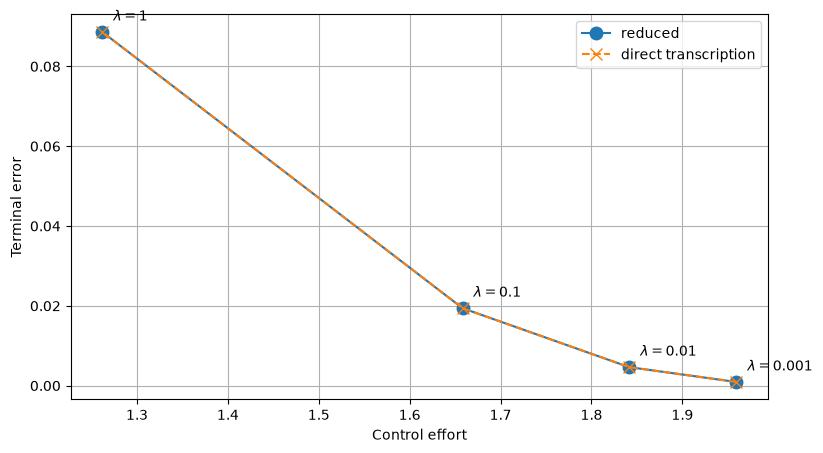

In [34]:
plt.figure(figsize=(9, 5))

for formulation, style in [
    ("reduced", "o-"),
    ("direct transcription", "x--"),
]:
    data = comparison_hw5[
        comparison_hw5["formulation"] == formulation
    ]

    plt.plot(
        data["control_effort"],
        data["terminal_error"],
        style,
        label=formulation,
        markersize=9,
    )

for _, row in comparison_hw5[
    comparison_hw5["formulation"] == "reduced"
].iterrows():
    plt.annotate(
        rf"$\lambda={row['lambda']:g}$",
        (row["control_effort"], row["terminal_error"]),
        xytext=(8, 8),
        textcoords="offset points",
    )

plt.xlabel("Control effort")
plt.ylabel("Terminal error")
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Вывод:</span>

при увеличении $\lambda$ от $0.001$ до $1$ затраты управления уменьшаются с $1.9595$ до $1.2619$, а ошибка конечного состояния возрастает с $0.00091$ до $0.08861$, что отражает компромисс между точностью достижения цели и затратами на управление. Обе постановки дают практически одинаковые результаты, невязка динамики пренебрежимо мала.

## Итог

В конце напишите **10–15 предложений**.

Нужны ответы на вопросы:

- чем reduced formulation отличается от direct transcription;
- почему в этой задаче они должны приводить к одному и тому же минимуму;
- что происходит с вычислительной стоимостью при росте $N$;
- как различались методы `scipy.optimize`;
- почему `success=True` недостаточно для сравнения качества решений;
- чем ошибка дискретизации отличается от ошибки optimizer'а;
- что изменилось после появления ограничения на состояние;
- когда вы бы выбрали reduced formulation, а когда direct transcription.

Не делайте вывод «метод X всегда быстрее метода Y» по одному примеру. В наших экспериментах SciPy использует в основном универсальные алгоритмы и численные производные; специализированные sparse-солверы для больших задач direct transcription могут вести себя совсем иначе.

## Перед сдачей

- выполните `Restart Kernel → Run All`;
- не вписывайте численные результаты вручную;
- таблицы должны собираться из результатов расчётов;
- подпишите оси и легенды;
- повторяющийся код вынесите в функции.

<span style="color:red">Итог:</span>

В reduced formulation переменными оптимизации являются только значения управления, а траектория вычисляется по уравнениям динамики. В direct transcription состояния и управления оптимизируются одновременно, а динамика задаётся ограничениями-равенствами. При одинаковой дискретизации обе постановки описывают одну и ту же задачу, поэтому их глобальные минимумы должны совпадать. При увеличении $N$ размерность обеих задач растёт линейно: $N$ переменных в reduced formulation и $3N+2$ в direct transcription, при этом увеличивается и вычислительная стоимость. В наших экспериментах при $N=80$ reduced formulation потребовала $0.1652$ с, а direct transcription — $1.0948$ с, хотя при $N=10$ вторая постановка оказалась быстрее. При сгущении сетки значения функционала и оптимальные управления стабилизируются, а $J$ приближается к непрерывному оптимуму.

Методы L-BFGS-B, SLSQP и trust-constr обеспечили практически одинаковые значения $J\approx0.090019$, однако различались по времени выполнения и числу вычислений функции. Наименьшее время показал SLSQP в reduced formulation ($0.0079$ с), тогда как Powell получил существенно худшее значение $J\approx0.166941$ с относительным разрывом около $85.45\%$. Следовательно, `success=True` означает выполнение критерия остановки оптимизатора, но не гарантирует нахождения глобального минимума или высокого качества решения. Ошибка дискретизации связана с приближённым описанием динамики и сохраняется даже при точном решении дискретной задачи, тогда как ошибка оптимизации возникает из-за неточной остановки численного алгоритма. В эксперименте с методом Эйлера ошибка конечного состояния уменьшилась с $1.373\cdot10^{-3}$ до $1.49\cdot10^{-4}$ при сгущении сетки от $N=10$ до $N=80$.

После введения ограничения $|x_2(t)|\leq0.8$ обе постановки дали практически одинаковые решения без нарушений, однако в direct transcription ограничение оказалось удобнее задавать непосредственно через bounds на переменные состояния. Увеличение веса управления $\lambda$ привело к снижению затрат управления и росту ошибки достижения целевого состояния, что подтвердило наличие компромисса между этими величинами. Для задач с простой динамикой и ограничениями преимущественно на управление я бы выбрал reduced formulation, а при наличии сложных ограничений на состояния — direct transcription. При этом полученные результаты сравнения скорости относятся только к рассматриваемой задаче, заданным tolerances и реализации SciPy с преимущественно численными производными, поскольку специализированные разреженные алгоритмы могут существенно изменить соотношение вычислительных затрат.